# Paper 02: Adam & AdamW (Decoupled Weight Decay Optimizer)
**Authors**: Diederik P. Kingma & Jimmy Ba (2014) / Ilya Loshchilov & Frank Hutter (2017)

---

## 1. The Historical Problem (What Broke Before This?)
Original **Adam** was celebrated as the ultimate optimizer because it combined momentum (first moment $m_t$) with coordinate-wise adaptive variance scaling (second moment $v_t$).

However, when practitioners added **L2 regularization** (weight decay $\lambda$), they added $\lambda \theta$ directly into the gradient $g_t$.
Look at the resulting update equation:
$$\theta_t = \theta_{t-1} - \frac{\eta}{\sqrt{v_t} + \epsilon} (m_t + \lambda \theta_{t-1})$$

The weight decay was divided by $\sqrt{v_t}$!
- Parameters with large historical gradients had their weight decay suppressed.
- Parameters with tiny gradients were excessively penalized.

## 2. The First-Principles Solution (AdamW)
True weight decay is an exponential shrinkage on the weights themselves, independent of gradient scale.
We simply **decouple** weight decay from the gradient moments:
$$\theta_t = \theta_{t-1} - \eta \lambda \theta_{t-1} - \frac{\eta}{\sqrt{\hat{v}_t} + \epsilon} \hat{m}_t$$

In this exercise, you will implement `AdamW.step()` from scratch in `model.py` and verify it here.

---
## Setup
`%autoreload 2` ensures any edits you make in `model.py` are immediately refreshed.

In [20]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from model import AdamW
import tests

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Part 1: State Initialization & Decoupled Weight Decay

Implement `step()` in `model.py`.
First, we verify that state buffers (`step`, `exp_avg`, `exp_avg_sq`) are initialized, and that weight decay acts independently of gradients.

In [21]:
print("Testing State Initialization:")
tests.test_state_initialization(AdamW)

print("\nTesting Decoupled Weight Decay:")
tests.test_decoupled_weight_decay(AdamW)

Testing State Initialization:
  [PASS] State initialization ('step', 'exp_avg', 'exp_avg_sq') is correct!

Testing Decoupled Weight Decay:
  [PASS] Decoupled weight decay applied independently of gradients (w: 10.0 -> 9.9500)!


True

---
## Part 2: Bias Correction & PyTorch Equivalence

We test that early steps are correctly un-biased by dividing by $(1 - \beta_1^t)$ and $(1 - \beta_2^t)$, and that our mathematical trajectory matches PyTorch's native `torch.optim.AdamW` to within $< 10^{-6}$.

In [22]:
print("Testing Step 1 Analytical Update:")
tests.test_bias_correction_step_one(AdamW)

print("\nTesting Exact Equivalence to PyTorch Native AdamW:")
tests.test_equivalence_to_pytorch(AdamW)

Testing Step 1 Analytical Update:
  [PASS] Step 1 bias correction matches exact analytical formula!

Testing Exact Equivalence to PyTorch Native AdamW:
  [PASS] Custom AdamW is mathematically identical to PyTorch AdamW (max diff: 0.00e+00)!


True

---
## Part 3: The Rosenbrock Banana Valley Contest!

The Rosenbrock function $f(x, y) = (1 - x)^2 + 100(y - x^2)^2$ has a notoriously curved, narrow parabolic valley.
We start at $(-1.5, 2.0)$ and visualize how your AdamW navigates the canyon compared to vanilla SGD!

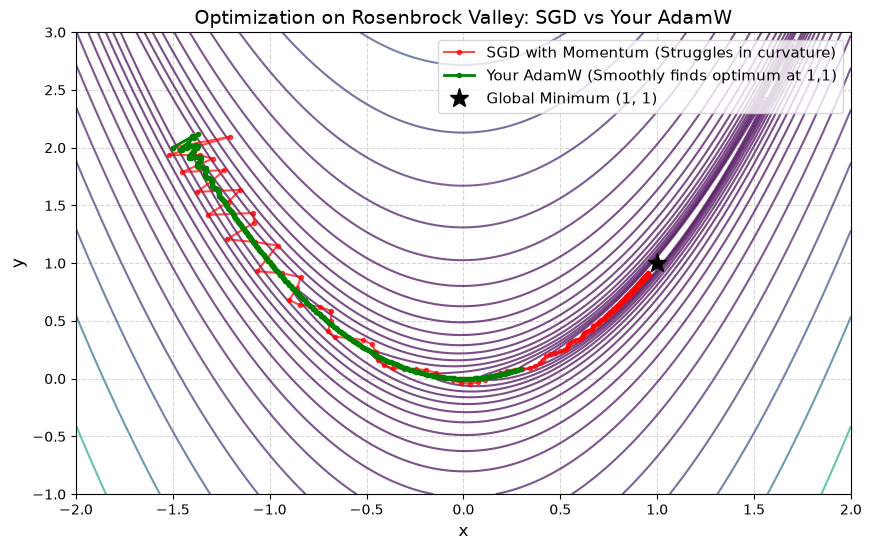

In [23]:
# Track trajectories for SGD vs your AdamW
def optimize_path(opt_builder, steps=250):
    xy = torch.tensor([-1.5, 2.0], requires_grad=True)
    opt = opt_builder([xy])
    trajectory = [xy.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad()
        loss = (1.0 - xy[0])**2 + 100.0 * (xy[1] - xy[0]**2)**2
        loss.backward()
        opt.step()
        trajectory.append(xy.detach().clone().numpy())
    return np.array(trajectory)

path_adamw = optimize_path(lambda p: AdamW(p, lr=0.1, weight_decay=0.01))
path_sgd = optimize_path(lambda p: torch.optim.SGD(p, lr=0.0019, momentum=0.9))

# Create Contour Plot
x_vals = np.linspace(-2.0, 2.0, 400)
y_vals = np.linspace(-1.0, 3.0, 400)
X, Y = np.meshgrid(x_vals, y_vals)
Z = (1.0 - X)**2 + 100.0 * (Y - X**2)**2

plt.figure(figsize=(10, 6))
plt.contour(X, Y, Z, levels=np.logspace(-0.5, 3.5, 20), cmap='viridis', alpha=0.7)
plt.plot(path_sgd[:, 0], path_sgd[:, 1], 'r.-', label='SGD with Momentum (Struggles in curvature)', alpha=0.7)
plt.plot(path_adamw[:, 0], path_adamw[:, 1], 'g.-', label='Your AdamW (Smoothly finds optimum at 1,1)', linewidth=2)
plt.plot(1.0, 1.0, 'k*', markersize=14, label='Global Minimum (1, 1)')
plt.title('Optimization on Rosenbrock Valley: SGD vs Your AdamW', fontsize=14)
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

---
## Part 4: Neural Network Single-Batch Overfit Gate

We train a deep network initialized with your Paper 01 Kaiming Init using your Paper 02 AdamW optimizer.
Watch the loss collapse to near zero!

In [24]:
from pathlib import Path
import sys

sys.path.insert(0, str(Path().resolve().parents[1]))

import torch
import torch.nn as nn
from core.layers import init_weights
from model import AdamW

torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(32, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 4),
)
init_weights(model, nonlinearity="relu")

opt = AdamW(model.parameters(), lr=0.01, weight_decay=0.01)
loss_fn = nn.MSELoss()

batch_x = torch.randn(8, 32)
batch_y = torch.randn(8, 4)

print("Training single batch for 50 steps using your AdamW:")
for step in range(1, 51):
  opt.zero_grad()
  pred = model(batch_x)
  loss = loss_fn(pred, batch_y)
  loss.backward()
  opt.step()
  if step == 1 or step % 10 == 0:
    print(f"  Step {step:02d} | Loss: {loss.item():.6f}")

assert loss.item() < 0.01, f"Loss did not drop below 0.01 (loss={loss.item():.4f})"
print(f"\n[PASS] Overfit gate passed! Final loss: {loss.item():.6f} (< 0.01)")

Training single batch for 50 steps using your AdamW:
  Step 01 | Loss: 2.140380
  Step 10 | Loss: 0.065438
  Step 20 | Loss: 0.020229
  Step 30 | Loss: 0.004736
  Step 40 | Loss: 0.001356
  Step 50 | Loss: 0.000826

[PASS] Overfit gate passed! Final loss: 0.000826 (< 0.01)
